**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits
from src.representation import (fit_pca, pca_project, pca_reconstruct,
                                load_autoencoder, ae_encode, ae_decode)

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

**Célula 2 – testar as funções do PCA:**

In [2]:
pca = fit_pca(X_train)

Z_ours = pca_project(pca, X_val, 16)                
Z_sklearn = pca.transform(X_val)[:, :16]            
print("Projeção igual ao scikit-learn?", np.allclose(Z_ours, Z_sklearn, atol=1e-4))

X_rec = pca_reconstruct(pca, Z_ours)
print("Forma do código:", Z_ours.shape, "| forma da reconstrução:", X_rec.shape)
print(f"MSE PCA-16 (validação): {np.mean((X_val - X_rec) ** 2):.5f}")   

Projeção igual ao scikit-learn? True
Forma do código: (10000, 16) | forma da reconstrução: (10000, 784)
MSE PCA-16 (validação): 0.02038


**Célula 3 – testar as funções do autoencoder (carregando do disco):**

In [3]:
ae16 = load_autoencoder(16, "models/ae_16.pt")     

Z_ae = ae_encode(ae16, X_val)                       
X_rec_ae = ae_decode(ae16, Z_ae)                    
print("Forma do código:", Z_ae.shape, "| forma da reconstrução:", X_rec_ae.shape)
print("Reconstrução entre 0 e 1?", X_rec_ae.min() >= 0, X_rec_ae.max() <= 1)
print(f"MSE AE-16 (validação): {np.mean((X_val - X_rec_ae) ** 2):.5f}")  

Forma do código: (10000, 16) | forma da reconstrução: (10000, 784)
Reconstrução entre 0 e 1? True True
MSE AE-16 (validação): 0.00977


**Célula 4 – espaço 2D do PCA vs código 2D do autoencoder:**

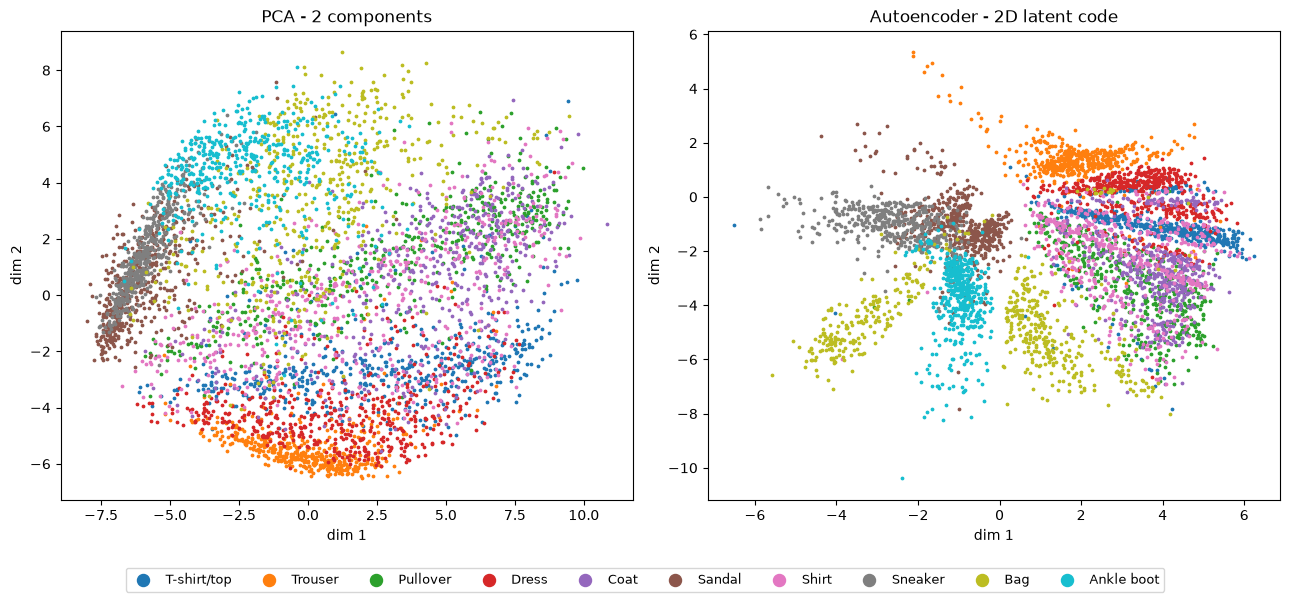

In [4]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_val), size=5000, replace=False)     
X_sub, y_sub = X_val[idx], y_val[idx]

ae2 = load_autoencoder(2, "models/ae_2.pt")
spaces = {
    "PCA - 2 components": pca_project(pca, X_sub, 2),
    "Autoencoder - 2D latent code": ae_encode(ae2, X_sub),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
cmap = plt.get_cmap("tab10")
for ax, (name, Z) in zip(axes, spaces.items()):
    for c in range(10):
        m = y_sub == c
        ax.scatter(Z[m, 0], Z[m, 1], s=3, color=cmap(c), label=CLASS_NAMES[c])
    ax.set_title(name)
    ax.set_xlabel("dim 1"); ax.set_ylabel("dim 2")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=10, markerscale=5, fontsize=9)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("results/figures/07_latent_2d_pca_vs_ae.png", dpi=150, bbox_inches="tight")
plt.show()